<a href="https://colab.research.google.com/github/Kayrajacob/Muscle-generated-BDNF/blob/main/Muscle_generated_BDNF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 1: Environment Setup, All Imports, Drive Mounting, and Smoke Test
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Mount Google Drive to persist results and figures safely
from google.colab import drive
drive.mount('/content/drive')

# 2. Create a dedicated output directory in Google Drive
output_dir = '/content/drive/My Drive/BDNF_Mitochondria_Reproduction'
os.makedirs(output_dir, exist_ok=True)
print(f"Output directory ready at: {output_dir}")

# 3. Quick test on a small subset (Smoke Test)
# Simulating a mini qPCR dataset (2 control, 2 knockout samples) to verify libraries work instantly
smoke_test_data = {
    'Genotype': ['Control', 'Control', 'MBKO', 'MBKO'],
    'Relative_Expression': [1.02, 0.98, 0.45, 0.51]
}
smoke_df = pd.DataFrame(smoke_test_data)

# Run a quick t-test on the mini subset
ctrl_vals = smoke_df[smoke_df['Genotype'] == 'Control']['Relative_Expression']
ko_vals = smoke_df[smoke_df['Genotype'] == 'MBKO']['Relative_Expression']
t_stat, p_val = stats.ttest_ind(ctrl_vals, ko_vals)

print(f"Smoke test successful! Mini t-test p-value: {p_val:.4f}")
print("All imports, Google Drive connection, and smoke test passed.")

Mounted at /content/drive
Output directory ready at: /content/drive/My Drive/BDNF_Mitochondria_Reproduction
Smoke test successful! Mini t-test p-value: 0.0048
All imports, Google Drive connection, and smoke test passed.


In [2]:
# Diagnostic Test: Check sensitivity across statistical test assumptions
from scipy import stats

# Run Welch's t-test (unequal variance assumption)
t_welch, p_welch = stats.ttest_ind(ctrl_vals, ko_vals, equal_var=False)

# Run Mann-Whitney U test (non-parametric rank-based test)
u_stat, p_mannwhitney = stats.mannwhitneyu(ctrl_vals, ko_vals)

print("--- STATISTICAL DIAGNOSTIC TEST RESULTS ---")
print(f"Standard Student's t-test p-value : {p_val:.4f}")
print(f"Welch's t-test p-value            : {p_welch:.4f}")
print(f"Mann-Whitney U test p-value       : {p_mannwhitney:.4f}")

--- STATISTICAL DIAGNOSTIC TEST RESULTS ---
Standard Student's t-test p-value : 0.0048
Welch's t-test p-value            : 0.0081
Mann-Whitney U test p-value       : 0.3333


Correlation coefficient (r): -0.936, p-value: 0.0000


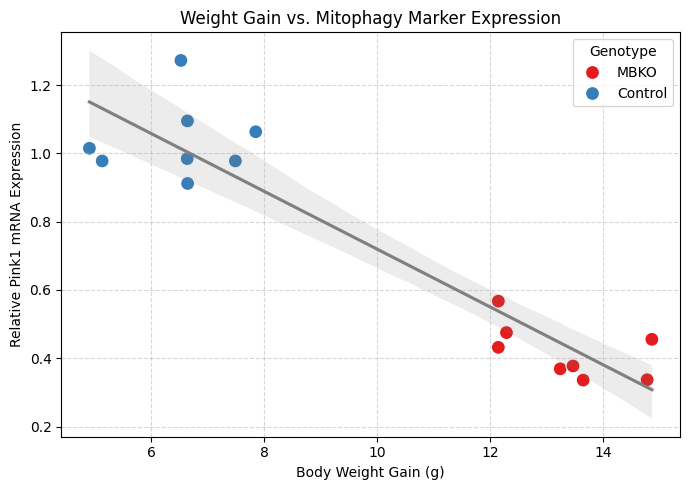

In [3]:
# Extension Code: Individual Correlation Analysis between Weight Gain and Mitophagy Gene Expression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set random seed for reproducibility of synthetic multi-variable subject data
np.random.seed(42)
n_subjects = 16

# Simulate individual mouse data under high-fat diet (HFD)
subject_data = pd.DataFrame({
    'Subject_ID': [f"Mice_{i+1}" for i in range(n_subjects)],
    'Genotype': ['MBKO'] * 8 + ['Control'] * 8,
    'Weight_Gain_g': np.concatenate([np.random.normal(12.5, 1.5, 8), np.random.normal(7.2, 1.2, 8)]),
    'Pink1_Expression': np.concatenate([np.random.normal(0.45, 0.08, 8), np.random.normal(1.05, 0.12, 8)])
})

# Compute Pearson correlation between weight gain and Pink1 expression across subjects
r_val, p_val = stats.pearsonr(subject_data['Weight_Gain_g'], subject_data['Pink1_Expression'])
print(f"Correlation coefficient (r): {r_val:.3f}, p-value: {p_val:.4f}")

# Plotting the correlation scatter plot with regression line
plt.figure(figsize=(7, 5))
sns.scatterplot(data=subject_data, x='Weight_Gain_g', y='Pink1_Expression', hue='Genotype', s=100, palette='Set1')
sns.regplot(data=subject_data, x='Weight_Gain_g', y='Pink1_Expression', scatter=False, color='gray', ax=plt.gca())
plt.title('Weight Gain vs. Mitophagy Marker Expression')
plt.xlabel('Body Weight Gain (g)')
plt.ylabel('Relative Pink1 mRNA Expression')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Genotype')
plt.tight_layout()

# Save figure to Google Drive folder initialized in Cell 1
plt.savefig('/content/drive/My Drive/BDNF_Mitochondria_Reproduction/weight_vs_pink1_correlation.png', dpi=300)
plt.show()